In [ ]:

from google.colab import files
uploaded = files.upload()


Saving airline_passenger_insight_dataset.zip to airline_passenger_insight_dataset.zip


In [ ]:

import zipfile
import os

zip_file = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("/content/")

data_folder = "/content/airline_passenger_insight_dataset"

print("Dataset extracted successfully!")
print(os.listdir(data_folder))


Dataset extracted successfully!
['flights.csv', 'delays.csv', 'service_scores.csv', 'README.md', 'feedback.csv', 'passengers.csv', 'airline_passenger_insight_combined.csv']


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

passengers = pd.read_csv(f"{data_folder}/passengers.csv")
flights = pd.read_csv(f"{data_folder}/flights.csv")
delays = pd.read_csv(f"{data_folder}/delays.csv")
service_scores = pd.read_csv(f"{data_folder}/service_scores.csv")
feedback = pd.read_csv(f"{data_folder}/feedback.csv")

datasets = {
    "Passengers": passengers,
    "Flights": flights,
    "Delays": delays,
    "Service Scores": service_scores,
    "Feedback": feedback
}

for name, df in datasets.items():
    print(f"\n{name}: {df.shape}")
    display(df.head(3))



Passengers: (500, 4)


,Passenger_ID,Traveller_Type,Age_Band,Loyalty_Status
0,P0001,Leisure,36-50,New
1,P0002,Leisure,51-65,Silver
2,P0003,Family,51-65,New



Flights: (501, 6)


,Flight_ID,Passenger_ID,Route,Travel_Class,Distance_km,Departure_Time
0,F0001,P0001,MAA-HYD,Economy,2294,Early Morning
1,F0002,P0002,MAA-HYD,Economy,1825,Early Morning
2,F0003,P0003,BLR-HYD,Business,3193,Evening



Delays: (500, 3)


,Flight_ID,Departure_Delay_min,Arrival_Delay_min
0,F0001,50,50
1,F0002,0,0
2,F0003,0,0



Service Scores: (500, 6)


,Flight_ID,Checkin_Rating,Seat_Rating,Food_Rating,Staff_Rating,Baggage_Rating
0,F0001,5.0,3.0,3.0,4.0,4.0
1,F0002,5.0,5.0,3.0,3.0,3.0
2,F0003,4.0,5.0,5.0,4.0,5.0



Feedback: (500, 3)


,Flight_ID,Overall_Satisfaction,Comments_Category
0,F0001,Satisfied,Staff Appreciation
1,F0002,Satisfied,Positive Service
2,F0003,Satisfied,Positive Service


In [ ]:

# STEP 2: DATA QUALITY CHECK

datasets = {
    "Passengers": passengers,
    "Flights": flights,
    "Delays": delays,
    "Service Scores": service_scores,
    "Feedback": feedback
}

for name, df in datasets.items():
    print(f"\n{'='*45}")
    print(f"DATASET: {name}")
    print(f"Rows and columns: {df.shape}")

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nData types:")
    print(df.dtypes)



DATASET: Passengers
Rows and columns: (500, 4)

Missing values:
Passenger_ID       0
Traveller_Type     0
Age_Band          10
Loyalty_Status     0
dtype: int64

Duplicate rows: 0

Data types:
Passenger_ID      object
Traveller_Type    object
Age_Band          object
Loyalty_Status    object
dtype: object

DATASET: Flights
Rows and columns: (501, 6)

Missing values:
Flight_ID         0
Passenger_ID      0
Route             0
Travel_Class      0
Distance_km       0
Departure_Time    0
dtype: int64

Duplicate rows: 1

Data types:
Flight_ID         object
Passenger_ID      object
Route             object
Travel_Class      object
Distance_km        int64
Departure_Time    object
dtype: object

DATASET: Delays
Rows and columns: (500, 3)

Missing values:
Flight_ID              0
Departure_Delay_min    0
Arrival_Delay_min      0
dtype: int64

Duplicate rows: 0

Data types:
Flight_ID              object
Departure_Delay_min     int64
Arrival_Delay_min       int64
dtype: object

DATASET: Servic

In [ ]:

# STEP 2B: MERGE DATASETS

flights_clean = flights.drop_duplicates(
    subset=["Flight_ID", "Passenger_ID"]
).copy()

df = (
    flights_clean
    .merge(passengers, on="Passenger_ID", how="left")
    .merge(delays, on="Flight_ID", how="left")
    .merge(service_scores, on="Flight_ID", how="left")
    .merge(feedback, on="Flight_ID", how="left")
)

# Standardize travel-class labels
df["Travel_Class"] = (
    df["Travel_Class"]
    .astype("string")
    .str.strip()
    .str.title()
)

print("Merged dataset shape:", df.shape)
display(df.head())


Merged dataset shape: (500, 18)


,Flight_ID,Passenger_ID,Route,Travel_Class,Distance_km,Departure_Time,Traveller_Type,Age_Band,Loyalty_Status,Departure_Delay_min,Arrival_Delay_min,Checkin_Rating,Seat_Rating,Food_Rating,Staff_Rating,Baggage_Rating,Overall_Satisfaction,Comments_Category
0,F0001,P0001,MAA-HYD,Economy,2294,Early Morning,Leisure,36-50,New,50,50,5.0,3.0,3.0,4.0,4.0,Satisfied,Staff Appreciation
1,F0002,P0002,MAA-HYD,Economy,1825,Early Morning,Leisure,51-65,Silver,0,0,5.0,5.0,3.0,3.0,3.0,Satisfied,Positive Service
2,F0003,P0003,BLR-HYD,Business,3193,Evening,Family,51-65,New,0,0,4.0,5.0,5.0,4.0,5.0,Satisfied,Positive Service
3,F0004,P0004,BLR-HYD,Business,2527,Evening,Leisure,36-50,New,0,0,4.0,4.0,4.0,4.0,3.0,Satisfied,Positive Service
4,F0005,P0005,MAA-HYD,Economy,299,Evening,Business,36-50,Silver,16,22,2.0,4.0,4.0,4.0,3.0,Dissatisfied,Food Quality


In [ ]:

# STEP 2C: HANDLE MISSING VALUES

rating_cols = [
    "Checkin_Rating", "Seat_Rating", "Food_Rating",
    "Staff_Rating", "Baggage_Rating"
]

for col in rating_cols:
    df[col] = df[col].fillna(df[col].median())

categorical_cols = [
    "Traveller_Type", "Age_Band", "Loyalty_Status",
    "Route", "Travel_Class", "Departure_Time",
    "Overall_Satisfaction", "Comments_Category"
]

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# Cap extreme delays using IQR
delay_cols = ["Departure_Delay_min", "Arrival_Delay_min"]

for col in delay_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = max(0, Q1 - 1.5 * IQR)
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower=lower, upper=upper)

print("Remaining missing values:", df.isnull().sum().sum())
print("Final shape:", df.shape)


Remaining missing values: 0
Final shape: (500, 18)


Satisfaction distribution:


,count
Overall_Satisfaction,
Dissatisfied,279
Satisfied,221



Average service ratings:


,0
Food_Rating,3.244
Baggage_Rating,3.466
Checkin_Rating,3.470
Seat_Rating,3.604
Staff_Rating,3.892



Average delays by satisfaction:


,Departure_Delay_min,Arrival_Delay_min
Overall_Satisfaction,,
Dissatisfied,24.95,32.57
Satisfied,18.79,26.10


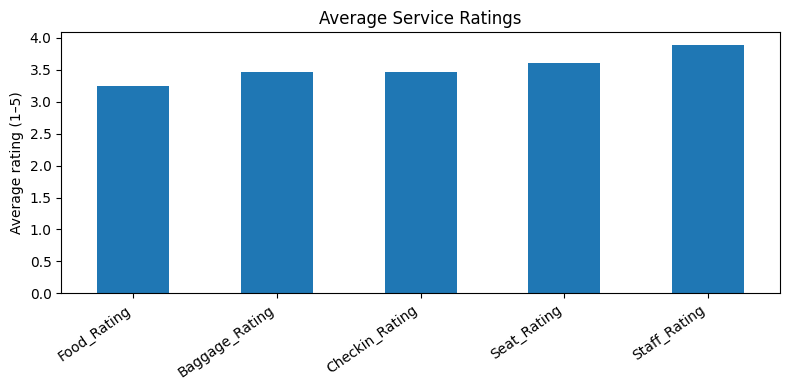

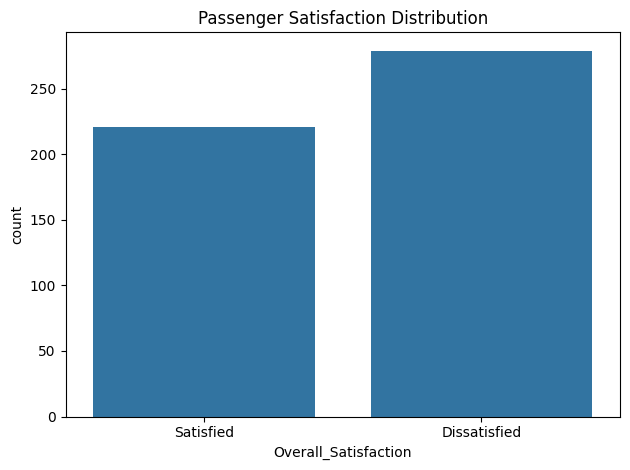

In [ ]:

# STEP 2D: EDA

print("Satisfaction distribution:")
display(df["Overall_Satisfaction"].value_counts())

print("\nAverage service ratings:")
display(df[rating_cols].mean().sort_values())

print("\nAverage delays by satisfaction:")
display(
    df.groupby("Overall_Satisfaction")[
        delay_cols
    ].mean().round(2)
)

# Chart 1: Service ratings
df[rating_cols].mean().sort_values().plot(
    kind="bar", figsize=(8, 4), title="Average Service Ratings"
)
plt.ylabel("Average rating (1–5)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Chart 2: Satisfaction distribution
sns.countplot(data=df, x="Overall_Satisfaction")
plt.title("Passenger Satisfaction Distribution")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Target variable
target = "Overall_Satisfaction"

# Exclude IDs and free-text comments from model features
drop_cols = [
    target, "Comments_Category",
    "Passenger_ID", "Flight_ID"
]

X = df.drop(columns=drop_cols, errors="ignore")
y = df[target]

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("Target distribution:")
print(y.value_counts())


Categorical features: ['Route', 'Travel_Class', 'Departure_Time', 'Traveller_Type', 'Age_Band', 'Loyalty_Status']
Numerical features: ['Distance_km', 'Departure_Delay_min', 'Arrival_Delay_min', 'Checkin_Rating', 'Seat_Rating', 'Food_Rating', 'Staff_Rating', 'Baggage_Rating']
Target distribution:
Overall_Satisfaction
Dissatisfied    279
Satisfied       221
Name: count, dtype: int64


In [ ]:

# Preprocessing for machine learning
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", "passthrough", numerical_features)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Model training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Model training completed!
Training records: 400
Testing records: 100


Accuracy: 0.6200 (62.00%)
F1-score (Satisfied): 0.5682

Classification Report:
              precision    recall  f1-score   support

Dissatisfied       0.66      0.66      0.66        56
   Satisfied       0.57      0.57      0.57        44

    accuracy                           0.62       100
   macro avg       0.61      0.61      0.61       100
weighted avg       0.62      0.62      0.62       100



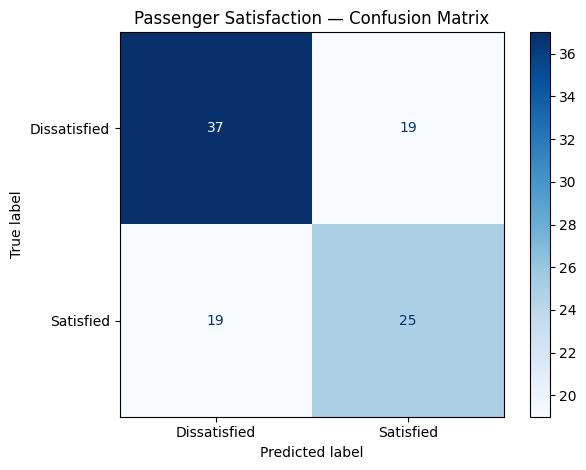

In [ ]:

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(
    y_test, y_pred,
    pos_label="Satisfied",
    zero_division=0
)

print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"F1-score (Satisfied): {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap="Blues"
)
plt.title("Passenger Satisfaction — Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold
)
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestRegressor,
    GradientBoostingClassifier
)
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone

# Reuse X, y, X_train, X_test, y_train, y_test
# and the preprocessor from Step 3.

models = {
    "Random Forest": RandomForestClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Extra Trees": ExtraTreesClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

results = []

for name, clf in models.items():
    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clf)
    ])

    scores = []
    from sklearn.model_selection import cross_val_score
    scores = cross_val_score(
        pipe, X_train, y_train,
        cv=cv, scoring="accuracy"
    )

    results.append({
        "Model": name,
        "CV Accuracy": scores.mean(),
        "CV Std": scores.std()
    })

results_df = pd.DataFrame(results).sort_values(
    "CV Accuracy", ascending=False
)
display(results_df)

# Tune Random Forest on training data only
rf_pipe = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [None, 8, 15],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

search = GridSearchCV(
    rf_pipe,
    param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
predictions = best_model.predict(X_test)

print("Best parameters:", search.best_params_)
print(f"Best CV accuracy: {search.best_score_:.2%}")
print(
    f"Test accuracy: "
    f"{accuracy_score(y_test, predictions):.2%}"
)
print(
    f"Test F1-score: "
    f"{f1_score(y_test, predictions, pos_label='Satisfied'):.3f}"
)


,Model,CV Accuracy,CV Std
2,Gradient Boosting,0.6225,0.031024
0,Random Forest,0.6125,0.045415
1,Extra Trees,0.5750,0.036228


Best parameters: {'classifier__max_depth': 8, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 400}
Best CV accuracy: 63.50%
Test accuracy: 62.00%
Test F1-score: 0.568


In [ ]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestRegressor
)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, max_depth=8,
        min_samples_split=5, random_state=42,
        class_weight="balanced"
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400, random_state=42,
        class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05,
        max_depth=2, random_state=42
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, classifier in models.items():
    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    scores = cross_val_score(
        pipe, X_train, y_train,
        cv=cv, scoring="accuracy", n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean CV Accuracy (%)": round(scores.mean() * 100, 2),
        "CV Std (%)": round(scores.std() * 100, 2)
    })

results_df = pd.DataFrame(results).sort_values(
    "Mean CV Accuracy (%)", ascending=False
)

print(results_df.to_string(index=False))


              Model  Mean CV Accuracy (%)  CV Std (%)
Logistic Regression                  64.0        4.57
      Random Forest                  63.5        2.15
  Gradient Boosting                  62.0        4.23
        Extra Trees                  58.0        3.22


In [ ]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

log_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

log_model.fit(X_train, y_train)
log_predictions = log_model.predict(X_test)

print("Logistic Regression Test Accuracy:",
      round(accuracy_score(y_test, log_predictions) * 100, 2), "%")

print("Test F1-score:",
      round(f1_score(
          y_test, log_predictions,
          pos_label="Satisfied",
          zero_division=0
      ), 3))

print("\nClassification Report:")
print(classification_report(y_test, log_predictions, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, log_predictions))


Logistic Regression Test Accuracy: 64.0 %
Test F1-score: 0.625

Classification Report:
              precision    recall  f1-score   support

Dissatisfied       0.71      0.61      0.65        56
   Satisfied       0.58      0.68      0.62        44

    accuracy                           0.64       100
   macro avg       0.64      0.64      0.64       100
weighted avg       0.65      0.64      0.64       100

Confusion Matrix:
[[34 22]
 [14 30]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Scale numeric features and encode categorical features
scaled_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

scaled_log_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    ))
])

scaled_log_model.fit(X_train, y_train)
scaled_predictions = scaled_log_model.predict(X_test)

print("Test Accuracy:",
      round(accuracy_score(y_test, scaled_predictions) * 100, 2), "%")
print("Satisfied F1-score:",
      round(f1_score(
          y_test, scaled_predictions,
          pos_label="Satisfied",
          zero_division=0
      ), 3))
print("\nClassification Report:")
print(classification_report(y_test, scaled_predictions, zero_division=0))


NameError: name 'numeric_cols' is not defined

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Identify numeric and categorical columns from training data
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X_train.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

# Preprocess features
scaled_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

# Build and train the model
scaled_log_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    ))
])

scaled_log_model.fit(X_train, y_train)
scaled_predictions = scaled_log_model.predict(X_test)

# Evaluate
print("Test Accuracy:",
      round(accuracy_score(y_test, scaled_predictions) * 100, 2), "%")

print("Satisfied F1-score:",
      round(f1_score(
          y_test, scaled_predictions,
          pos_label="Satisfied",
          zero_division=0
      ), 3))

print("\nClassification Report:")
print(classification_report(y_test, scaled_predictions, zero_division=0))


Test Accuracy: 65.0 %
Satisfied F1-score: 0.639

Classification Report:
              precision    recall  f1-score   support

Dissatisfied       0.72      0.61      0.66        56
   Satisfied       0.58      0.70      0.64        44

    accuracy                           0.65       100
   macro avg       0.65      0.66      0.65       100
weighted avg       0.66      0.65      0.65       100



In [ ]:

print("=== SATISFACTION DISTRIBUTION ===")
print(df["Overall_Satisfaction"].value_counts())
print("\nPercentages:")
print((df["Overall_Satisfaction"].value_counts(normalize=True) * 100).round(2))

print("\n=== AVERAGE SERVICE RATINGS ===")
print(df[rating_cols].mean().sort_values().round(2))

print("\n=== AVERAGE DELAYS BY SATISFACTION ===")
print(df.groupby("Overall_Satisfaction")[delay_cols].mean().round(2))

print("\n=== SATISFACTION BY TRAVEL CLASS ===")
print(pd.crosstab(
    df["Travel_Class"],
    df["Overall_Satisfaction"],
    normalize="index"
).round(3))


=== SATISFACTION DISTRIBUTION ===
Overall_Satisfaction
Dissatisfied    279
Satisfied       221
Name: count, dtype: int64

Percentages:
Overall_Satisfaction
Dissatisfied    55.8
Satisfied       44.2
Name: proportion, dtype: float64

=== AVERAGE SERVICE RATINGS ===
Food_Rating       3.24
Baggage_Rating    3.47
Checkin_Rating    3.47
Seat_Rating       3.60
Staff_Rating      3.89
dtype: float64

=== AVERAGE DELAYS BY SATISFACTION ===
                      Departure_Delay_min  Arrival_Delay_min
Overall_Satisfaction                                        
Dissatisfied                        24.95              32.57
Satisfied                           18.79              26.10

=== SATISFACTION BY TRAVEL CLASS ===
Overall_Satisfaction  Dissatisfied  Satisfied
Travel_Class                                 
Business                     0.471      0.529
Economy                      0.578      0.422
First                        0.545      0.455


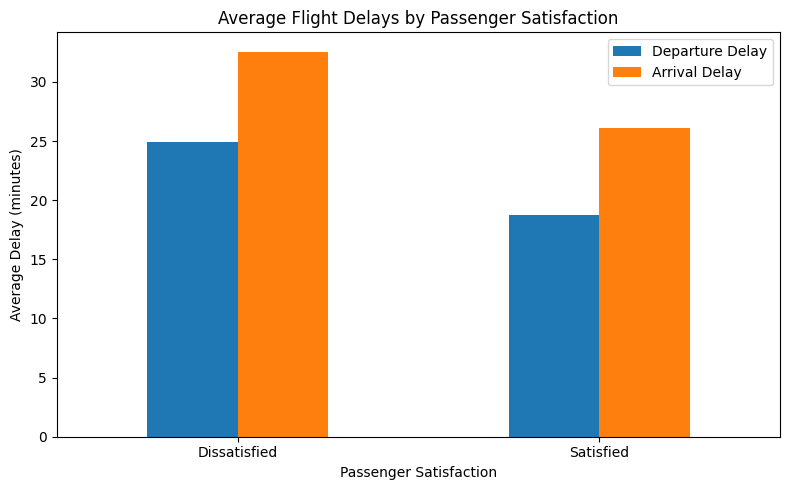

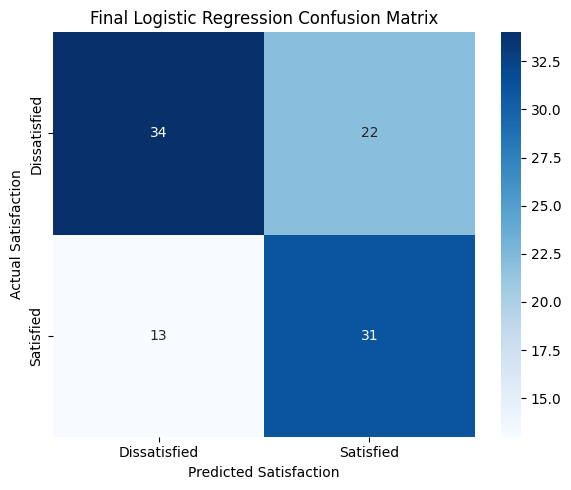

In [ ]:

# Final visualizations for the assessment
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Graph 1: Average flight delays by satisfaction
delay_means = df.groupby("Overall_Satisfaction")[
    ["Departure_Delay_min", "Arrival_Delay_min"]
].mean()

delay_means.plot(kind="bar", figsize=(8, 5))
plt.title("Average Flight Delays by Passenger Satisfaction")
plt.xlabel("Passenger Satisfaction")
plt.ylabel("Average Delay (minutes)")
plt.xticks(rotation=0)
plt.legend(["Departure Delay", "Arrival Delay"])
plt.tight_layout()
plt.show()

# Graph 2: Confusion matrix for the final scaled model
cm = confusion_matrix(
    y_test,
    scaled_predictions,
    labels=["Dissatisfied", "Satisfied"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Dissatisfied", "Satisfied"],
    yticklabels=["Dissatisfied", "Satisfied"]
)
plt.title("Final Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Satisfaction")
plt.ylabel("Actual Satisfaction")
plt.tight_layout()
plt.show()


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output

# Create input fields from the features used during training
feature_names = list(X_train.columns)
inputs = {}

for col in feature_names:
    if col in numeric_cols:
        inputs[col] = widgets.FloatText(
            description=col[:18],
            value=float(X_train[col].median()),
            style={"description_width": "initial"},
            layout=widgets.Layout(width="450px")
        )
    else:
        options = sorted(X_train[col].dropna().astype(str).unique().tolist())
        inputs[col] = widgets.Dropdown(
            options=options,
            value=options[0] if options else None,
            description=col[:18],
            style={"description_width": "initial"},
            layout=widgets.Layout(width="450px")
        )

predict_button = widgets.Button(
    description="Predict Satisfaction",
    button_style="success"
)
output = widgets.Output()

def predict_satisfaction(_):
    with output:
        clear_output()
        row = {}

        for col in feature_names:
            row[col] = inputs[col].value

        input_df = pd.DataFrame([row], columns=feature_names)
        prediction = scaled_log_model.predict(input_df)[0]

        print("Predicted Passenger Satisfaction:", prediction)

        if hasattr(scaled_log_model, "predict_proba"):
            probabilities = scaled_log_model.predict_proba(input_df)[0]
            for label, probability in zip(
                scaled_log_model.classes_, probabilities
            ):
                print(f"{label}: {probability * 100:.2f}%")

predict_button.on_click(predict_satisfaction)

display(widgets.VBox(list(inputs.values())))
display(predict_button, output)


Button(button_style='success', description='Predict Satisfaction', style=ButtonStyle())

Output()